# 01 — Sanity checks

A short end-to-end smoke test of the SpecMatch engine. Unlike notebooks 02–05, which
**load saved benchmark results from `benchmarks/results/*.json`**, this notebook runs the
models live (that is its purpose: prove the installation works). Nothing here feeds the
reported benchmark numbers.

Checks:
1. environment + automatic device/dtype selection
2. tokenizer round-trip
3. baseline autoregressive generation
4. speculative generation
5. the **greedy parity property**: with an identical draft and target model, greedy
   speculative output is token-for-token identical to the baseline and the acceptance
   rate is 100%

It first uses `sshleifer/tiny-gpt2` (~0.1M params, runs anywhere), then the real
benchmark pair `distilgpt2` (draft) → `gpt2` (target).

In [1]:
import copy
import gc
import os
import sys
import time
from pathlib import Path

import torch
import transformers

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from specmatch import (GenConfig, SpecConfig, baseline_generate, speculative_generate,
                       resolve_device, resolve_dtype)
from specmatch.models import load_model, load_pair, load_tokenizer

torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | transformers {transformers.__version__}")
device = resolve_device()
dtype = resolve_dtype("auto", device)
print(f"auto-detected device: {device} | dtype: {dtype}")

OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


python 3.11.2 | torch 2.14.0+cpu | transformers 5.17.0
auto-detected device: cpu | dtype: torch.bfloat16


## Tokenizer sanity

In [2]:
tok = load_tokenizer("sshleifer/tiny-gpt2")
text = "speculative decoding verifies draft tokens"
ids = tok(text)["input_ids"]
print("vocab size:", tok.vocab_size, "| eos token id:", tok.eos_token_id)
print("first ids:", ids[:12])
print("round-trip:", repr(tok.decode(ids)))

vocab size: 50257 | eos token id: 50256
first ids: [4125, 3129, 876, 39938, 3326, 6945, 4538, 16326]
round-trip: 'speculative decoding verifies draft tokens'


## Baseline generation + greedy parity

`baseline_generate` is plain autoregressive decoding with a KV cache: one forward pass
per token. We then run `speculative_generate` with a **deep copy of the same model as the
draft**. Every proposal must then be accepted (identical distributions), and in greedy
mode the output must be *exactly* the baseline output — this is the correctness contract,
also covered by `tests/test_speculative.py`.

In [3]:
tiny = load_model("sshleifer/tiny-gpt2", torch.float32, torch.device("cpu"))
prompt = "The meaning of life is"
cfg = GenConfig(max_new_tokens=16, temperature=0.0)

text_b, stats_b = baseline_generate(tiny, tok, prompt, cfg)
print(f"baseline   : {text_b!r}")
print(f"             {stats_b.new_tokens} tok in {stats_b.wall_time:.2f}s "
      f"({stats_b.tokens_per_sec:.1f} tok/s) | forwards={stats_b.target_forwards}")

Loading weights:   0%|          | 0/29 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: sshleifer/tiny-gpt2
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
transformer.h.{0, 1}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


baseline   : ' stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs'
             16 tok in 0.10s (160.4 tok/s) | forwards=16


In [4]:
draft = copy.deepcopy(tiny)  # identical weights -> acceptance must be 100%
scfg = SpecConfig(max_new_tokens=16, temperature=0.0, num_speculative_tokens=4)
text_s, stats_s = speculative_generate(draft, tiny, tok, prompt, scfg)

print(f"speculative: {text_s!r}")
print(f"acceptance : {stats_s.accepted}/{stats_s.proposed} = {stats_s.acceptance_rate:.1%}")
print(f"tokens per target forward: {stats_s.mean_tokens_per_target_forward:.2f}")
assert stats_s.token_ids == stats_b.token_ids, "greedy parity violated!"
print("greedy parity: PASS (identical token ids)")

speculative: ' stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs stairs'
acceptance : 12/12 = 100.0%
tokens per target forward: 3.20
greedy parity: PASS (identical token ids)


## The real pair: `distilgpt2` (82M) draft → `gpt2` (124M) target

Loaded in bf16 on CPU (auto-detected). One short greedy run of each engine on the same
prompt. Note: in **bf16** the batched verify matmul rounds logits slightly differently
than single-token decode, so near-tied greedy argmax can flip and the two outputs may
diverge even though the algorithm is exact; parity holds exactly in fp32
(`python scripts/run_speculative.py --dtype float32 --compare`) and in the fp32 unit
tests. See README §Correctness for details.

In [5]:
del tiny, draft
gc.collect()

tok2, draft2, target2 = load_pair("distilgpt2", "gpt2", dtype, device)
print(f"draft  params: {sum(p.numel() for p in draft2.parameters()) / 1e6:.1f}M")
print(f"target params: {sum(p.numel() for p in target2.parameters()) / 1e6:.1f}M")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

draft  params: 81.9M
target params: 124.4M


In [6]:
prompt = "Question: Why is the sky blue during the day?\nAnswer:"
cfg = GenConfig(max_new_tokens=24, temperature=0.0)
scfg = SpecConfig(**cfg.to_dict(), num_speculative_tokens=4)

text_b, sb = baseline_generate(target2, tok2, prompt, cfg, device)
text_s, ss = speculative_generate(draft2, target2, tok2, prompt, scfg, device)

print(f"baseline   : {sb.tokens_per_sec:5.1f} tok/s | ttft {sb.ttft:.2f}s")
print(f"speculative: {ss.tokens_per_sec:5.1f} tok/s | acc {ss.acceptance_rate:.0%} | "
      f"tok/fwd {ss.mean_tokens_per_target_forward:.2f}")
print(f"speedup on this single prompt: {sb.wall_time / ss.wall_time:.2f}x")
print()
print("baseline output   :", repr(text_b[:90]))
print("speculative output:", repr(text_s[:90]))
overlap = sum(a == b for a, b in zip(sb.token_ids, ss.token_ids)) / max(len(sb.token_ids), 1)
print(f"\nprefix token overlap in bf16: {overlap:.0%}")
print("any divergence comes from bf16 argmax flips, not the accept/reject logic (which")
print("is exact in fp32 - verified by the test suite).")

baseline   :   8.3 tok/s | ttft 1.28s
speculative:   4.5 tok/s | acc 44% | tok/fwd 2.40
speedup on this single prompt: 0.54x

baseline output   : " The sky blue is a sign of the sun's brightness.\nThe sun is the light of the sun, and the"
speculative output: " The sky blue is a sign of the sun's brightness. The sun is the light of the sun, and the "

prefix token overlap in bf16: 50%
any divergence comes from bf16 argmax flips, not the accept/reject logic (which
is exact in fp32 - verified by the test suite).


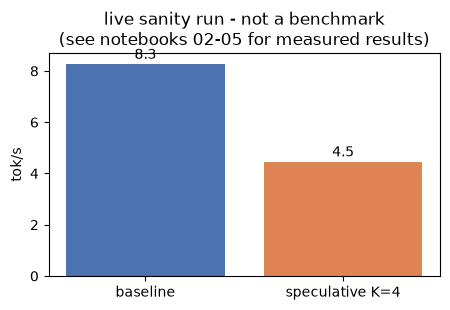

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4.6, 3.2))
vals = [sb.tokens_per_sec, ss.tokens_per_sec]
ax.bar(["baseline", "speculative K=4"], vals, color=["#4c72b0", "#dd8452"])
ax.set_ylabel("tok/s")
ax.set_title("live sanity run - not a benchmark\n(see notebooks 02-05 for measured results)")
for i, v in enumerate(vals):
    ax.text(i, v + 0.2, f"{v:.1f}", ha="center")
fig.tight_layout()
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports" / "figures" / "fig01_sanity_speed.png", dpi=150)
plt.show()

## Summary

- models, tokenizer, baseline loop, and speculative loop all work end-to-end;
- greedy parity holds exactly when draft ≡ target (and for any draft in fp32 — see tests);
- the real benchmark pair loads and runs on this hardware.

Next: `02_acceptance_rate.ipynb` analyses the saved benchmark results.